3. سوالات تکلیف

In [ ]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


sys.path.append(str(Path.cwd().parent / 'src'))

from data_utils import get_regression_data
from train_3_2 import run_experiment

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


3-2 روش های منظم سازی برای کاهش بیش برازش

3-2-1 مدل اول: L1 و L2 (روی داده ی رگرسیون)

3-2-1-1 ﻳﻚ MLP ﺑﺎ ﻳﻚ ﻻﻳﻪ ﻣﺨﻔﻲ ۵۰ ﻧﺮﻭﻥ (ﻛﻪ ﺩﭼﺎﺭ ﺑﻴﺶ ﺑﺮﺍﺯﺵ ﻣﻲ ﺷﻮﺩ) ﺭﻭﻱ ﺩﺍﺩﻩ ﻱ ﺭﮔﺮﺳﻴﻮﻥ ﺁﻣﻮﺯﺵ ﺩﻫﻴﺪ. ﺳﭙﺲ ﻣﻨﻈﻢ ﺳﺎﺯﻱ L2 ﺭﺍ ﺑﺎ ﺿﺮﺍﻳﺐ {0, 10^-5, 10^-4, 10^-3, 10^-2}∈  λ اعمال کنید.

الف) ﻧﻤﻮﺩﺍﺭ ﺗﺎﺑﻊ ﻫﺰﻳﻨﻪ ﺭﻭﻱ ﺁﻣﻮﺯﺵ ﻭ ﺁﺯﻣﻮﻥ ﺭﺍ ﺑﺮ ﺣﺴﺐ ﺩﻭﺭﻩ ﻫﺎ ﺑﺮﺍﻱ ﻫﺮ λ ﺭﺳﻢ ﻛﻨﻴﺪ.

In [3]:
class OneHiddenLayer50(nn.Module):
    def __init__(self, input_dim=1, hidden_size=50, **kwargs):
        super().__init__()
        self.hidden = nn.Linear(input_dim, hidden_size)
        self.relu = nn.ReLU()
        self.out = nn.Linear(hidden_size, 1)
    def forward(self, x):
        return self.out(self.relu(self.hidden(x)))
    
    def get_first_layer_weights(self):
        """برای محاسبه نرم وزن‌ها"""
        return self.hidden.weight.data


In [4]:
X_train, X_test, y_train, y_test, train_loader, test_loader = get_regression_data(
    test_size=0.25, noise_std=0.2, batch_size=16, random_state=42
)


Train shape (regression): (150, 1)



--- Running with lambda = 0 ---
version - 3
Epoch 01/200 | Train MSE: 0.4874 | Test MSE: 0.3759
Epoch 10/200 | Train MSE: 0.1372 | Test MSE: 0.1273
Epoch 20/200 | Train MSE: 0.0934 | Test MSE: 0.0850
Epoch 30/200 | Train MSE: 0.0598 | Test MSE: 0.0585
Epoch 40/200 | Train MSE: 0.0435 | Test MSE: 0.0584
Epoch 50/200 | Train MSE: 0.0423 | Test MSE: 0.0385
Epoch 60/200 | Train MSE: 0.0374 | Test MSE: 0.0383
Epoch 70/200 | Train MSE: 0.0408 | Test MSE: 0.0355
Epoch 80/200 | Train MSE: 0.0498 | Test MSE: 0.0661
Epoch 90/200 | Train MSE: 0.0342 | Test MSE: 0.0468
Epoch 100/200 | Train MSE: 0.0364 | Test MSE: 0.0403
Epoch 110/200 | Train MSE: 0.0398 | Test MSE: 0.0333
Epoch 120/200 | Train MSE: 0.0458 | Test MSE: 0.0435
Epoch 130/200 | Train MSE: 0.0434 | Test MSE: 0.0310
Epoch 140/200 | Train MSE: 0.0382 | Test MSE: 0.0327
Epoch 150/200 | Train MSE: 0.0495 | Test MSE: 0.0392
Epoch 160/200 | Train MSE: 0.0378 | Test MSE: 0.0367
Epoch 170/200 | Train MSE: 0.0413 | Test MSE: 0.0506
Epoch 180/2

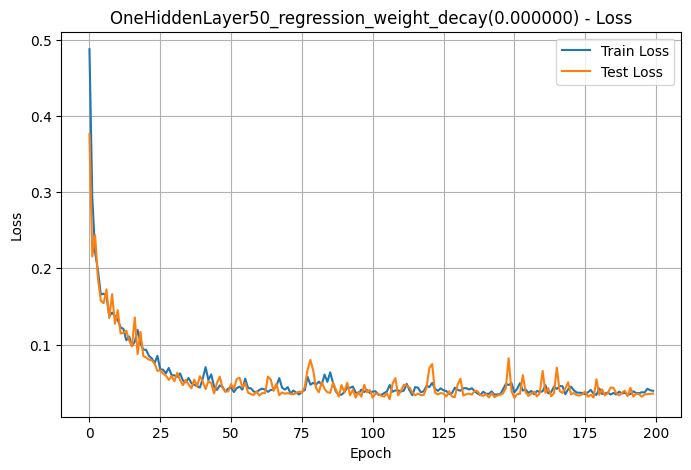


--- Running with lambda = 1e-05 ---
version - 3
Epoch 01/200 | Train MSE: 0.3014 | Test MSE: 0.2467
Epoch 10/200 | Train MSE: 0.1065 | Test MSE: 0.0941
Epoch 20/200 | Train MSE: 0.0599 | Test MSE: 0.0616
Epoch 30/200 | Train MSE: 0.0465 | Test MSE: 0.0379
Epoch 40/200 | Train MSE: 0.0494 | Test MSE: 0.0537
Epoch 50/200 | Train MSE: 0.0375 | Test MSE: 0.0334
Epoch 60/200 | Train MSE: 0.0470 | Test MSE: 0.0427
Epoch 70/200 | Train MSE: 0.0385 | Test MSE: 0.0364
Epoch 80/200 | Train MSE: 0.0397 | Test MSE: 0.0412
Epoch 90/200 | Train MSE: 0.0331 | Test MSE: 0.0390
Epoch 100/200 | Train MSE: 0.0398 | Test MSE: 0.0340
Epoch 110/200 | Train MSE: 0.0407 | Test MSE: 0.0368
Epoch 120/200 | Train MSE: 0.0392 | Test MSE: 0.0453
Epoch 130/200 | Train MSE: 0.0362 | Test MSE: 0.0422
Epoch 140/200 | Train MSE: 0.0376 | Test MSE: 0.0422
Epoch 150/200 | Train MSE: 0.0374 | Test MSE: 0.0391
Epoch 160/200 | Train MSE: 0.0386 | Test MSE: 0.0319
Epoch 170/200 | Train MSE: 0.0353 | Test MSE: 0.0361
Epoch 1

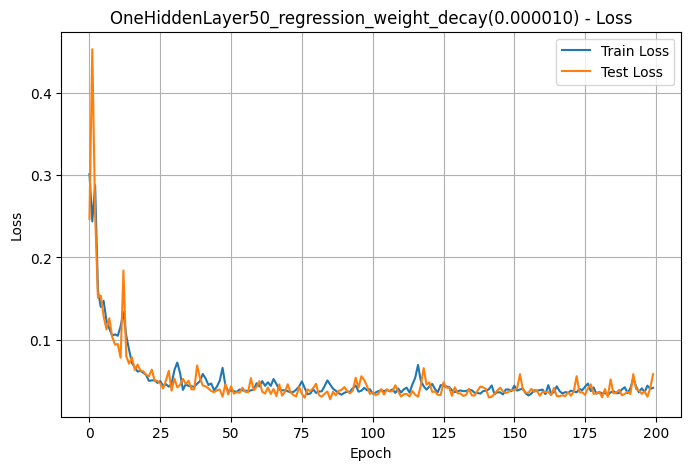


--- Running with lambda = 0.0001 ---
version - 3
Epoch 01/200 | Train MSE: 0.5996 | Test MSE: 0.4481
Epoch 10/200 | Train MSE: 0.1554 | Test MSE: 0.1594
Epoch 20/200 | Train MSE: 0.0935 | Test MSE: 0.1193
Epoch 30/200 | Train MSE: 0.0766 | Test MSE: 0.0747
Epoch 40/200 | Train MSE: 0.0963 | Test MSE: 0.0562
Epoch 50/200 | Train MSE: 0.0481 | Test MSE: 0.0523
Epoch 60/200 | Train MSE: 0.0457 | Test MSE: 0.0489
Epoch 70/200 | Train MSE: 0.0407 | Test MSE: 0.0371
Epoch 80/200 | Train MSE: 0.0375 | Test MSE: 0.0370
Epoch 90/200 | Train MSE: 0.0391 | Test MSE: 0.0351
Epoch 100/200 | Train MSE: 0.0565 | Test MSE: 0.0565
Epoch 110/200 | Train MSE: 0.0352 | Test MSE: 0.0328
Epoch 120/200 | Train MSE: 0.0404 | Test MSE: 0.0362
Epoch 130/200 | Train MSE: 0.0364 | Test MSE: 0.0322
Epoch 140/200 | Train MSE: 0.0470 | Test MSE: 0.0359
Epoch 150/200 | Train MSE: 0.0375 | Test MSE: 0.0346
Epoch 160/200 | Train MSE: 0.0376 | Test MSE: 0.0350
Epoch 170/200 | Train MSE: 0.0398 | Test MSE: 0.0314
Epoch 

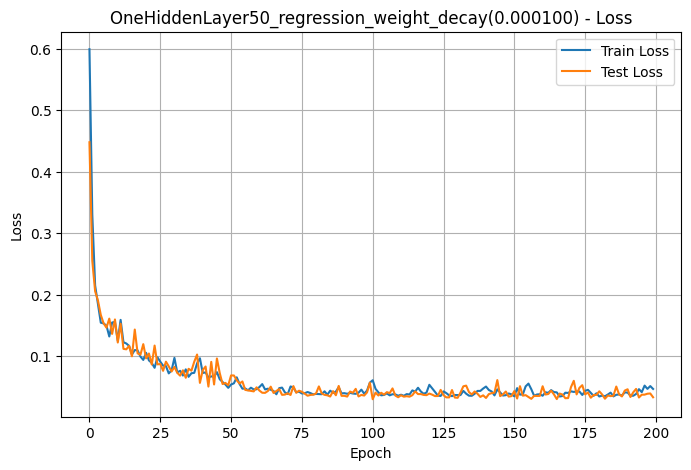


--- Running with lambda = 0.001 ---
version - 3
Epoch 01/200 | Train MSE: 0.3560 | Test MSE: 0.3337
Epoch 10/200 | Train MSE: 0.1434 | Test MSE: 0.1790
Epoch 20/200 | Train MSE: 0.1051 | Test MSE: 0.1046
Epoch 30/200 | Train MSE: 0.0923 | Test MSE: 0.0770
Epoch 40/200 | Train MSE: 0.0624 | Test MSE: 0.0676
Epoch 50/200 | Train MSE: 0.0646 | Test MSE: 0.0660
Epoch 60/200 | Train MSE: 0.0472 | Test MSE: 0.0534
Epoch 70/200 | Train MSE: 0.0441 | Test MSE: 0.0392
Epoch 80/200 | Train MSE: 0.0551 | Test MSE: 0.0466
Epoch 90/200 | Train MSE: 0.0380 | Test MSE: 0.0406
Epoch 100/200 | Train MSE: 0.0391 | Test MSE: 0.0381
Epoch 110/200 | Train MSE: 0.0453 | Test MSE: 0.0373
Epoch 120/200 | Train MSE: 0.0431 | Test MSE: 0.0347
Epoch 130/200 | Train MSE: 0.0388 | Test MSE: 0.0333
Epoch 140/200 | Train MSE: 0.0491 | Test MSE: 0.0427
Epoch 150/200 | Train MSE: 0.0407 | Test MSE: 0.0383
Epoch 160/200 | Train MSE: 0.0426 | Test MSE: 0.0342
Epoch 170/200 | Train MSE: 0.0371 | Test MSE: 0.0376
Epoch 1

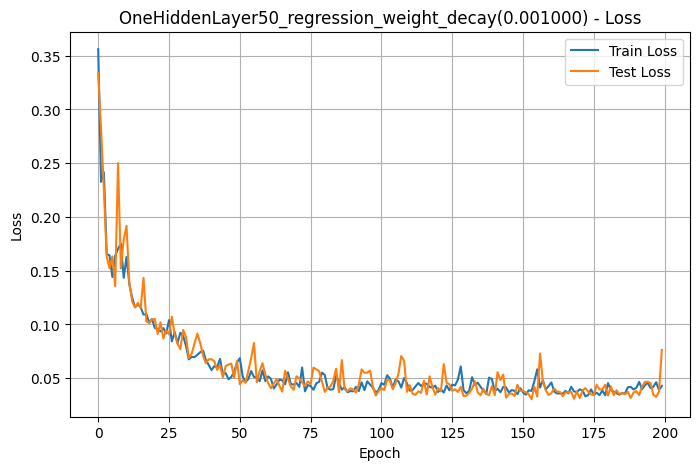


--- Running with lambda = 0.01 ---
version - 3
Epoch 01/200 | Train MSE: 0.5659 | Test MSE: 0.3910
Epoch 10/200 | Train MSE: 0.1505 | Test MSE: 0.1712
Epoch 20/200 | Train MSE: 0.1285 | Test MSE: 0.1303
Epoch 30/200 | Train MSE: 0.1098 | Test MSE: 0.1098
Epoch 40/200 | Train MSE: 0.0794 | Test MSE: 0.0977
Epoch 50/200 | Train MSE: 0.0763 | Test MSE: 0.0909
Epoch 60/200 | Train MSE: 0.0759 | Test MSE: 0.0856
Epoch 70/200 | Train MSE: 0.0681 | Test MSE: 0.0880
Epoch 80/200 | Train MSE: 0.0636 | Test MSE: 0.0848
Epoch 90/200 | Train MSE: 0.0577 | Test MSE: 0.0557
Epoch 100/200 | Train MSE: 0.0546 | Test MSE: 0.0584
Epoch 110/200 | Train MSE: 0.0590 | Test MSE: 0.0809
Epoch 120/200 | Train MSE: 0.0546 | Test MSE: 0.0792
Epoch 130/200 | Train MSE: 0.0537 | Test MSE: 0.0603
Epoch 140/200 | Train MSE: 0.0551 | Test MSE: 0.0677
Epoch 150/200 | Train MSE: 0.0519 | Test MSE: 0.0622
Epoch 160/200 | Train MSE: 0.0538 | Test MSE: 0.0579
Epoch 170/200 | Train MSE: 0.0514 | Test MSE: 0.0541
Epoch 18

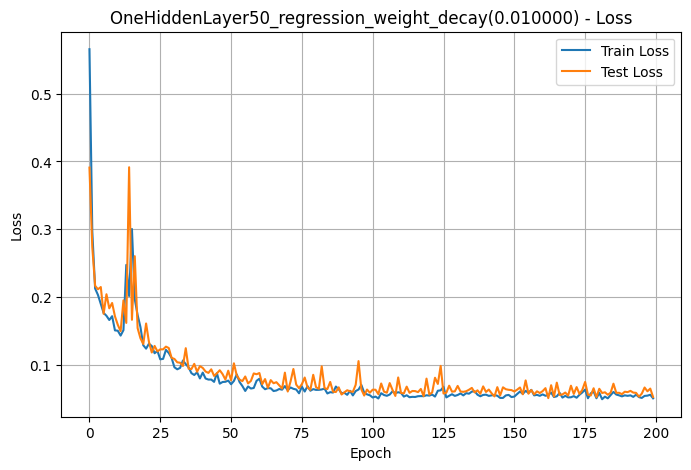

In [8]:
lambda_values = [0, 1e-5, 1e-4, 1e-3, 1e-2]
results = []
for lam in lambda_values:
    print(f"\n--- Running with lambda = {lam} ---")
    
    # فراخوانی run_experiment
    # توجه: فرض می‌کنیم run_experition را طوری اصلاح کرده‌اید که پارامتر weight_decay را بگیرد
    # و در ساخت optimizer از آن استفاده کند. در غیر این صورت، کد زیر کار نمی‌کند.
    history, model = run_experiment(
        model_class=OneHiddenLayer50,
        train_loader=train_loader,
        test_loader=test_loader,
        val_loader=None,              # بدون اعتبارسنجی
        lr=0.01,
        epochs=200,
        optimizer_name="Adam",
        criterion_name="MSELoss",
        dataset_name="regression",
        plot_loss=True,               # برای ذخیره نمودار loss
        plot_accuracy=False,
        plot_decision=False,
        save_model=False,
        # پارامترهای اختصاصی
        model_architecture="1x50",
        complexity_metric=50,
        noise_std=0.2,
        weight_decay=lam,
    )
    
    # محاسبه نرم وزن‌های لایه اول
    w = model.get_first_layer_weights().cpu().numpy().flatten()
    weight_norm = float(torch.norm(torch.tensor(w), p=2))
    
    results.append({
        "lambda": lam,
        "train_mse": history['train_loss'][-1],
        "test_mse": history['test_loss'][-1],
        "weight_norm": weight_norm
    })


ب) بهترین  λ ﺍﺯ ﻧﻈﺮ ﺧﻄﺎﻱ ﺁﺯﻣﻮﻥ ﻛﺪﺍﻡ ﺍﺳﺖ؟ ﺟﺪﻭﻝ ﻧﺘﺎﻳﺞ ﺷﺎﻣﻞ  λ، ﺧﻄﺎﻱ ﺁﻣﻮﺯﺵ، ﺧﻄﺎﻱ ﺁﺯﻣﻮﻥ ﻭ ﻧﺮﻡ ﻭﺯﻥ ﻫﺎ را تهیه ﻛﻨﻴﺪ .

In [9]:
df = pd.DataFrame(results)
print("\n=== Results for L2 Regularization ===")
print(df.to_string(index=False))



=== Results for L2 Regularization ===
 lambda  train_mse  test_mse  weight_norm
0.00000   0.039331  0.035681     3.175323
0.00001   0.041463  0.058111     2.956191
0.00010   0.046278  0.032730     2.344229
0.00100   0.042822  0.076290     1.935935
0.01000   0.050049  0.051977     0.988030


3-2-1-2 L1 را با ضرایب مشابه روی همان مدل آزمایش کنید.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from data_utils import get_regression_data

# مدل یکسان (یک لایه ۵۰ نرون)
class OneHiddenLayer50(nn.Module):
    def __init__(self, input_dim=1, hidden_size=50):
        super().__init__()
        self.hidden = nn.Linear(input_dim, hidden_size)
        self.relu = nn.ReLU()
        self.out = nn.Linear(hidden_size, 1)
    def forward(self, x):
        return self.out(self.relu(self.hidden(x)))
    def get_first_layer_weights(self):
        return self.hidden.weight.data.cpu().numpy().flatten()

# بارگذاری داده (همان تنظیمات قبل)
X_train, X_test, y_train, y_test, train_loader, test_loader = get_regression_data(
    test_size=0.25, noise_std=0.2, batch_size=16, random_state=42
)

lambda_values = [0, 1e-5, 1e-4, 1e-3, 1e-2]
results_l1 = []      # برای ذخیره نتایج L1
all_weights_l1 = []  # ذخیره وزن‌های لایه اول برای هر λ

for lam in lambda_values:
    print(f"\n--- L1 with lambda = {lam} ---")
    model = OneHiddenLayer50()
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    
    epochs = 200
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for Xb, yb in train_loader:
            optimizer.zero_grad()
            out = model(Xb)
            mse_loss = criterion(out, yb.view(-1,1))
            # محاسبه قلم L1 (مجموع قدر مطلق همه پارامترها)
            l1_penalty = sum(p.abs().sum() for p in model.parameters())
            loss = mse_loss + lam * l1_penalty
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        if (epoch+1) % 50 == 0:
            print(f"Epoch {epoch+1}, loss: {total_loss/len(train_loader):.6f}")
    
    # ارزیابی روی تست
    model.eval()
    test_loss = 0.0
    with torch.no_grad():
        for Xb, yb in test_loader:
            out = model(Xb)
            loss = criterion(out, yb.view(-1,1))
            test_loss += loss.item()
    test_mse = test_loss / len(test_loader)
    
    # ذخیره وزن‌ها
    w = model.get_first_layer_weights()
    weight_norm_l2 = np.linalg.norm(w)   # نرم L2 برای مقایسه
    results_l1.append({
        "lambda": lam,
        "test_mse": test_mse,
        "weight_norm_l1": weight_norm_l2,
        "weights": w
    })
    all_weights_l1.append(w)
    print(f"Test MSE: {test_mse:.6f}, Weight L2 norm: {weight_norm_l2:.4f}")

Train shape (regression): (150, 1)

--- L1 with lambda = 0 ---
Epoch 50, loss: 0.042846
Epoch 100, loss: 0.042564
Epoch 150, loss: 0.055495
Epoch 200, loss: 0.034921
Test MSE: 0.033825, Weight L2 norm: 2.9537

--- L1 with lambda = 1e-05 ---
Epoch 50, loss: 0.051118
Epoch 100, loss: 0.041746
Epoch 150, loss: 0.038379
Epoch 200, loss: 0.040035
Test MSE: 0.036752, Weight L2 norm: 2.3170

--- L1 with lambda = 0.0001 ---
Epoch 50, loss: 0.045590
Epoch 100, loss: 0.056174
Epoch 150, loss: 0.040290
Epoch 200, loss: 0.041904
Test MSE: 0.031152, Weight L2 norm: 2.3309

--- L1 with lambda = 0.001 ---
Epoch 50, loss: 0.113251
Epoch 100, loss: 0.078854
Epoch 150, loss: 0.068677
Epoch 200, loss: 0.067815
Test MSE: 0.038324, Weight L2 norm: 1.4977

--- L1 with lambda = 0.01 ---
Epoch 50, loss: 0.214988
Epoch 100, loss: 0.164284
Epoch 150, loss: 0.151184
Epoch 200, loss: 0.149615
Test MSE: 0.065907, Weight L2 norm: 0.8118

=== Results for L1 Regularization ===
 lambda  test_mse  weight_norm_l2
0.0000

In [11]:

df_l1 = pd.DataFrame([{k:v for k,v in d.items() if k!='weights'} for d in results_l1])
print("\n=== Results for L1 Regularization ===")
print(df_l1.to_string(index=False))


=== Results for L1 Regularization ===
 lambda  test_mse  weight_norm_l2
0.00000  0.033825        2.953711
0.00001  0.036752        2.316951
0.00010  0.031152        2.330884
0.00100  0.038324        1.497689
0.01000  0.065907        0.811838


الف) تفاوت تاثیر L1 و L2 را روی توزیع وزنها (مثلا هیستوگرام وزن های لایه ی اول) نشان دهید. کدام یک منجر به پراکندگی (sparsity) وزن ها میشود؟

Training L2 with lambda=0.0001...
Train shape (regression): (150, 1)
L2 weights shape: (50,), L2 norm: 1.5916
Training L1 with lambda=0.0001...
L1 weights shape: (50,), L2 norm: 1.6398


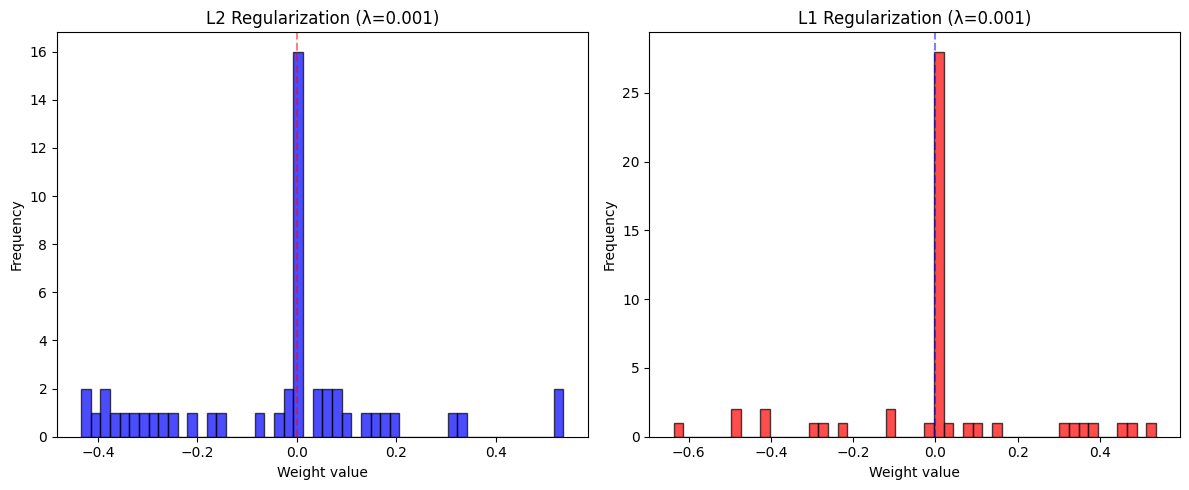

In [22]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from data_utils import get_regression_data

# مدل یکسان
class OneHiddenLayer50(nn.Module):
    def __init__(self, input_dim=1, hidden_size=50):
        super().__init__()
        self.hidden = nn.Linear(input_dim, hidden_size)
        self.relu = nn.ReLU()
        self.out = nn.Linear(hidden_size, 1)
    def forward(self, x):
        return self.out(self.relu(self.hidden(x)))
    def get_first_layer_weights(self):
        return self.hidden.weight.data.cpu().numpy().flatten()

# ========== 1. استخراج وزن‌ها برای L2 با λ=0.0001 ==========
# (اگر قبلاً ذخیره نکرده‌اید، یک بار اجرا کنید)
print("Training L2 with lambda=0.0001...")
model_l2 = OneHiddenLayer50()
criterion = nn.MSELoss()
optimizer_l2 = torch.optim.Adam(model_l2.parameters(), lr=0.01, weight_decay=0.001)

X_train, X_test, y_train, y_test, train_loader, test_loader = get_regression_data(
    test_size=0.25, noise_std=0.2, batch_size=16, random_state=42
)

epochs = 200
for epoch in range(epochs):
    model_l2.train()
    for Xb, yb in train_loader:
        optimizer_l2.zero_grad()
        out = model_l2(Xb)
        loss = criterion(out, yb.view(-1,1))
        loss.backward()
        optimizer_l2.step()
    # (بدون نمایش پیشرفت)

weights_l2 = model_l2.get_first_layer_weights()
print(f"L2 weights shape: {weights_l2.shape}, L2 norm: {np.linalg.norm(weights_l2):.4f}")

# ========== 2. استخراج وزن‌ها برای L1 با λ=0.0001 ==========
# با استفاده از کد L1 که قبلاً داشتید (اما دقت کنید که برای λ=0.0001 اجرا شود)
# اگر نتایج L1 را قبلاً ذخیره کرده‌اید، می‌توانید از همان مدل استفاده کنید.
# در غیر این صورت، دوباره اجرا کنید:

print("Training L1 with lambda=0.0001...")
model_l1 = OneHiddenLayer50()
optimizer_l1 = torch.optim.Adam(model_l1.parameters(), lr=0.01)

lam = 0.001
for epoch in range(epochs):
    model_l1.train()
    for Xb, yb in train_loader:
        optimizer_l1.zero_grad()
        out = model_l1(Xb)
        mse_loss = criterion(out, yb.view(-1,1))
        l1_penalty = sum(p.abs().sum() for p in model_l1.parameters())
        loss = mse_loss + lam * l1_penalty
        loss.backward()
        optimizer_l1.step()

weights_l1 = model_l1.get_first_layer_weights()
print(f"L1 weights shape: {weights_l1.shape}, L2 norm: {np.linalg.norm(weights_l1):.4f}")

# ========== 3. رسم هیستوگرام مقایسه‌ای ==========
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.hist(weights_l2, bins=50, alpha=0.7, color='blue', edgecolor='black')
plt.title(f'L2 Regularization (λ=0.001)')
plt.xlabel('Weight value')
plt.ylabel('Frequency')
plt.axvline(x=0, color='red', linestyle='--', alpha=0.5)

plt.subplot(1,2,2)
plt.hist(weights_l1, bins=50, alpha=0.7, color='red', edgecolor='black')
plt.title(f'L1 Regularization (λ=0.001)')
plt.xlabel('Weight value')
plt.ylabel('Frequency')
plt.axvline(x=0, color='blue', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('L1_vs_L2_weight_distribution.png', dpi=150)
plt.show()

3-2-2 مدل دوم : early stoping (روی داده ی moons)

3-2-2-1 ﻳﻚ ﺷﺒﻜﻪ ﺑﺎ ﻇﺮﻓﻴﺖ ﺑﺎﻻ (ﻣﺜﻼ ً ﺩﻭ ﻻﻳﻪ ﻣﺨﻔﻲ ﻫﺮ ﻛﺪﺍﻡ ۱۰۰ ﻧﺮﻭﻥ) ﺭﻭﻱ ﺩﺍﺩﻩ ﻱ ﺭﮔﺮﺳﻴﻮﻥ ﺁﻣﻮﺯﺵ ﺩﻫﻴﺪ. ﺍﺯ ﻣﺠﻤﻮﻋﻪ ﻱ ﺍﻋﺘﺒﺎﺭﺳﻨﺠﻲ (%۲۰ ﺍﺯ ﺩﺍﺩﻩ ﻱ ﺁﻣﻮﺯﺵ) ﺑﺮﺍﻱ ﺍﻋﻤﺎﻝ early stopping ﺑﺎ ﻣﻌﻴﺎﺭ patience = 10 ﺩﻭﺭﻩ ﺍﺳﺘﻔﺎﺩﻩ ﻛﻨﻴﺪ.

الف) ﻧﻤﻮﺩﺍﺭ ﺧﻄﺎﻱ ﺁﻣﻮﺯﺵ ﻭ ﺍﻋﺘﺒﺎﺭﺳﻨﺠﻲ ﺭﺍ ﺑﺮ ﺣﺴﺐ ﺩﻭﺭﻩ ﺭﺳﻢ ﻛﻨﻴﺪ. ﺑﻬﺘﺮﻳﻦ ﺩﻭﺭﻩ ﺑﺮ ﺍﺳﺎﺱ ﺍﻋﺘﺒﺎﺭﺳﻨﺠﻲ ﻛﺠﺎﺳﺖ؟ ﻣﺪﻝ ﻧﻬﺎﻳﻲ ﭼﻪ ﺧﻄﺎﻳﻲ ﺭﻭﻱ ﺁﺯﻣﻮﻥ ﺩﺍﺭﺩ ؟

In [24]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split


In [25]:
# ------------------------------------------------------------
# 1. توابع کمکی (بارگذاری داده و رسم نمودار)
# ------------------------------------------------------------
def get_moons_data_with_val(n_samples=400, noise=0.1, val_ratio=0.2, batch_size=64, random_state=42):
    """
    بارگذاری moons و تقسیم به train, validation, test
    خروجی: train_loader, val_loader, test_loader
    """
    X, y = make_moons(n_samples=n_samples, noise=noise, random_state=random_state)
    y = y.astype(np.float32)
    
    # ابتدا split به train+val و test
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=0.2, random_state=random_state
    )
    # سپس split train+val به train و val
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=val_ratio, random_state=random_state
    )
    
    # تبدیل به تنسور
    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
    X_val_t = torch.tensor(X_val, dtype=torch.float32)
    y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)
    X_test_t = torch.tensor(X_test, dtype=torch.float32)
    y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)
    
    train_ds = TensorDataset(X_train_t, y_train_t)
    val_ds = TensorDataset(X_val_t, y_val_t)
    test_ds = TensorDataset(X_test_t, y_test_t)
    
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)
    
    print(f"Train samples: {len(train_ds)}, Val samples: {len(val_ds)}, Test samples: {len(test_ds)}")
    return train_loader, val_loader, test_loader


In [26]:

def plot_and_save_loss(train_hist, val_hist, title, filename):
    plt.figure(figsize=(8,5))
    plt.plot(train_hist, label='Train Loss')
    plt.plot(val_hist, label='Validation Loss')
    plt.axvline(x=len(train_hist)-1, color='gray', linestyle='--', alpha=0.5)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.savefig(filename, dpi=150)
    plt.show()


In [27]:
# ------------------------------------------------------------
# 2. تعریف مدل پرظرفیت (دو لایه مخفی 100 نرون)
# ------------------------------------------------------------
class HighCapacityNet(nn.Module):
    def __init__(self, input_dim=2, hidden1=100, hidden2=100):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden1)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.relu2 = nn.ReLU()
        self.out = nn.Linear(hidden2, 1)
    def forward(self, x):
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        return self.out(x)   # بدون sigmoid (برای BCEWithLogitsLoss)


In [28]:

# ------------------------------------------------------------
# 3. بارگذاری داده
# ------------------------------------------------------------
train_loader, val_loader, test_loader = get_moons_data_with_val(
    n_samples=400, noise=0.1, val_ratio=0.2, batch_size=64, random_state=42
)


Train samples: 256, Val samples: 64, Test samples: 80


Epoch  10 | Train Loss: 0.0448 | Val Loss: 0.0298
Epoch  20 | Train Loss: 0.0020 | Val Loss: 0.0165
Early stopping triggered at epoch 26

=== Early Stopping Results ===
Best epoch: 16
Test Loss: 0.0128, Test Accuracy: 100.00%


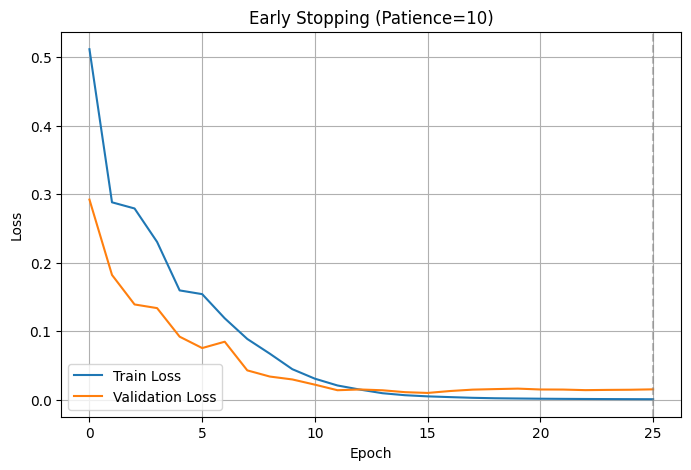

In [29]:
# ------------------------------------------------------------
# 4. آموزش با Early Stopping (Patience=10)
# ------------------------------------------------------------
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = HighCapacityNet().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

epochs = 200
patience = 10
best_val_loss = float('inf')
best_epoch = 0
patience_counter = 0
best_model_state = None

train_losses = []
val_losses = []

for epoch in range(epochs):
    # --- آموزش ---
    model.train()
    train_loss = 0.0
    for Xb, yb in train_loader:
        Xb, yb = Xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(Xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)
    train_losses.append(train_loss)
    
    # --- اعتبارسنجی ---
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for Xb, yb in val_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            out = model(Xb)
            loss = criterion(out, yb)
            val_loss += loss.item()
    val_loss /= len(val_loader)
    val_losses.append(val_loss)
    
    # --- Early stopping logic ---
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        patience_counter = 0
        best_model_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break
    
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1:3d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

# بارگذاری بهترین مدل
model.load_state_dict(best_model_state)
model.to(device)

# ارزیابی روی تست
model.eval()
test_loss = 0.0
correct = 0
total = 0
with torch.no_grad():
    for Xb, yb in test_loader:
        Xb, yb = Xb.to(device), yb.to(device)
        out = model(Xb)
        loss = criterion(out, yb)
        test_loss += loss.item()
        preds = (torch.sigmoid(out) > 0.5).float()
        correct += (preds == yb).sum().item()
        total += yb.size(0)
test_loss /= len(test_loader)
test_acc = correct / total * 100

print(f"\n=== Early Stopping Results ===")
print(f"Best epoch: {best_epoch}")
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.2f}%")

# رسم نمودار loss
plot_and_save_loss(train_losses, val_losses, 
                   f'Early Stopping (Patience={patience})', 
                   'early_stopping_loss.png')

ب) ﺍﮔﺮ ﺍﺯ early stopping ﺍﺳﺘﻔﺎﺩﻩ ﻧﻜﻨﻴﺪ، ﺧﻄﺎﻱ ﺁﺯﻣﻮﻥ ﭼﻘﺪﺭ ﺑﺪﺗﺮ ﻣﻲ ﺷﻮﺩ؟


--- Training without early stopping (200 epochs) ---
Epoch  10 | Train Loss: 0.0291 | Val Loss: 0.0284
Epoch  20 | Train Loss: 0.0019 | Val Loss: 0.0099
Epoch  30 | Train Loss: 0.0009 | Val Loss: 0.0156
Epoch  40 | Train Loss: 0.0005 | Val Loss: 0.0175
Epoch  50 | Train Loss: 0.0004 | Val Loss: 0.0190
Epoch  60 | Train Loss: 0.0003 | Val Loss: 0.0208
Epoch  70 | Train Loss: 0.0002 | Val Loss: 0.0221
Epoch  80 | Train Loss: 0.0002 | Val Loss: 0.0232
Epoch  90 | Train Loss: 0.0001 | Val Loss: 0.0244
Epoch 100 | Train Loss: 0.0001 | Val Loss: 0.0252
Epoch 110 | Train Loss: 0.0001 | Val Loss: 0.0266
Epoch 120 | Train Loss: 0.0001 | Val Loss: 0.0268
Epoch 130 | Train Loss: 0.0001 | Val Loss: 0.0272
Epoch 140 | Train Loss: 0.0001 | Val Loss: 0.0280
Epoch 150 | Train Loss: 0.0001 | Val Loss: 0.0293
Epoch 160 | Train Loss: 0.0000 | Val Loss: 0.0300
Epoch 170 | Train Loss: 0.0000 | Val Loss: 0.0306
Epoch 180 | Train Loss: 0.0000 | Val Loss: 0.0312
Epoch 190 | Train Loss: 0.0000 | Val Loss: 0.0

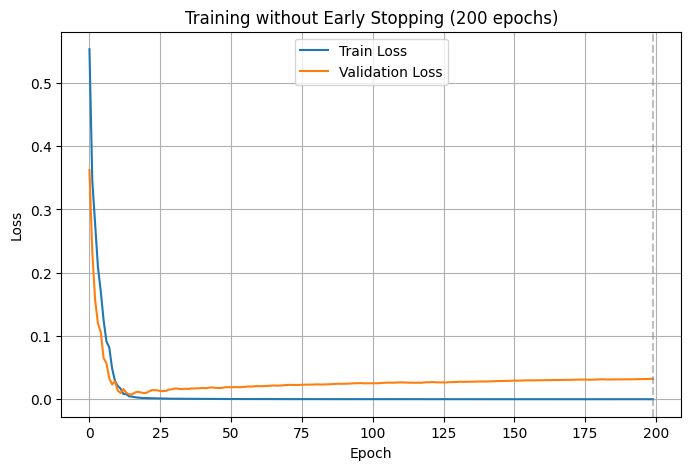

In [33]:

# ------------------------------------------------------------
# 5. آموزش بدون Early Stopping (200 دوره کامل) با ذخیره loss
# ------------------------------------------------------------
print("\n--- Training without early stopping (200 epochs) ---")
model2 = HighCapacityNet().to(device)
optimizer2 = optim.Adam(model2.parameters(), lr=0.01)

train_losses_no_es = []
val_losses_no_es = []

for epoch in range(200):
    # آموزش
    model2.train()
    train_loss = 0.0
    for Xb, yb in train_loader:
        Xb, yb = Xb.to(device), yb.to(device)
        optimizer2.zero_grad()
        out = model2(Xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer2.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)
    train_losses_no_es.append(train_loss)
    
    # اعتبارسنجی
    model2.eval()
    val_loss = 0.0
    with torch.no_grad():
        for Xb, yb in val_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            out = model2(Xb)
            loss = criterion(out, yb)
            val_loss += loss.item()
    val_loss /= len(val_loader)
    val_losses_no_es.append(val_loss)
    
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1:3d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

# ارزیابی روی تست
model2.eval()
test_loss_no_es = 0.0
correct_no_es = 0
with torch.no_grad():
    for Xb, yb in test_loader:
        Xb, yb = Xb.to(device), yb.to(device)
        out = model2(Xb)
        loss = criterion(out, yb)
        test_loss_no_es += loss.item()
        preds = (torch.sigmoid(out) > 0.5).float()
        correct_no_es += (preds == yb).sum().item()
test_loss_no_es /= len(test_loader)
test_acc_no_es = correct_no_es / total * 100

print(f"\n=== Without Early Stopping ===")
print(f"Test Loss: {test_loss_no_es:.4f}, Test Acc: {test_acc_no_es:.2f}%")

# رسم نمودار loss بدون Early Stopping
plot_and_save_loss(train_losses_no_es, val_losses_no_es,
                 'Training without Early Stopping (200 epochs)',
                 'no_early_stopping_loss.png')


In [34]:
# ------------------------------------------------------------
# 6. مقایسه نهایی
# ------------------------------------------------------------
print("\n=== Comparison ===")
print(f"With early stopping:  Test Loss = {test_loss:.4f}, Acc = {test_acc:.2f}%")
print(f"Without early stopping: Test Loss = {test_loss_no_es:.4f}, Acc = {test_acc_no_es:.2f}%")
print(f"Improvement: Loss reduction = {test_loss_no_es - test_loss:.4f}, Acc increase = {test_acc_no_es - test_acc:.2f}%")


=== Comparison ===
With early stopping:  Test Loss = 0.0128, Acc = 100.00%
Without early stopping: Test Loss = 0.0466, Acc = 98.75%
Improvement: Loss reduction = 0.0338, Acc increase = -1.25%


3-2-3 مدل سوم: dropout (روی داده moons)

3-2-3-1 ﻳﻚ MLP ﺑﺎ ﺩﻭ ﻻﻳﻪ ﻣﺨﻔﻲ (ﻫﺮ ﻛﺪﺍﻡ ۶۴ ﻧﺮﻭﻥ، ﻓﻌﺎﻝ ﺳﺎﺯﻱ ReLU) ﻭ ﺧﺮﻭﺟﻲ sigmoid ﺑﺮﺍﻱ ﺩﺳﺘﻪ ﺑﻨﺪﻱ ﺩﻭﺩﻭﻳﻲ ﻃﺮﺍﺣﻲ ﻛﻨﻴﺪ. ﻧﺮﺥ dropout ﺭﺍ ﺩﺭ{0,0.2,0.5,0.8} ﺑﺮﺍﻱ ﻫﺮ ﺩﻭ ﻻﻳﻪ ﻣﺨﻔﻲ ﺗﻐﻴﻴﺮ ﺩﻫﻴﺪ.

الف) ﺑﺮﺍﻱ ﻫﺮ ﻧﺮﺥ، ﻧﻤﻮﺩﺍﺭ ﺩﻗﺖ ﺁﻣﻮﺯﺵ ﻭ ﺁﺯﻣﻮﻥ ﺭﺍ ﺩﺭ ﻃﻮﻝ ﺩﻭﺭﻩ ﻫﺎ ﺭﺳﻢ ﻛﻨﻴﺪ.

ب) ﻛﺪﺍﻡ ﻧﺮﺥ ﺑﻬﺘﺮﻳﻦ ﺗﻌﻤﻴﻢ ﺩﻫﻲ ﺭﺍ ﺩﺍﺭﺩ؟ ﺁﻳﺎ dropout ﺑﺎﻋﺚ ﻛﺎﻫﺶ ﺩﻗﺖ ﺁﻣﻮﺯﺵ ﻣﻲ ﺷﻮﺩ؟ ﭼﺮﺍ؟

In [35]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split


In [36]:
# ------------------------------------------------------------
# 1. تابع بارگذاری داده moons (بدون validation)
# ------------------------------------------------------------
def get_moons_data(n_samples=400, noise=0.1, test_size=0.2, batch_size=64, random_state=42):
    X, y = make_moons(n_samples=n_samples, noise=noise, random_state=random_state)
    y = y.astype(np.float32)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)
    
    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
    X_test_t = torch.tensor(X_test, dtype=torch.float32)
    y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)
    
    train_ds = TensorDataset(X_train_t, y_train_t)
    test_ds = TensorDataset(X_test_t, y_test_t)
    
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)
    
    print(f"Train samples: {len(train_ds)}, Test samples: {len(test_ds)}")
    return train_loader, test_loader, X_train, y_train, X_test, y_test


In [37]:
# ------------------------------------------------------------
# 2. مدل با dropout (دو لایه مخفی 64 نرون)
# ------------------------------------------------------------
class DropoutMLP(nn.Module):
    def __init__(self, input_dim=2, hidden1=64, hidden2=64, dropout_rate=0.0):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden1)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout_rate)
        self.out = nn.Linear(hidden2, 1)
        
    def forward(self, x):
        x = self.relu1(self.fc1(x))
        x = self.dropout1(x)
        x = self.relu2(self.fc2(x))
        x = self.dropout2(x)
        return self.out(x)   # بدون sigmoid (برای BCEWithLogitsLoss)


In [38]:

# ------------------------------------------------------------
# 3. تابع آموزش و ارزیابی برای یک نرخ dropout
# ------------------------------------------------------------
def train_and_evaluate(dropout_rate, train_loader, test_loader, epochs=100, lr=0.01):
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    model = DropoutMLP(dropout_rate=dropout_rate).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    train_acc_history = []
    test_acc_history = []
    
    for epoch in range(epochs):
        # آموزش
        model.train()
        correct_train = 0
        total_train = 0
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(Xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
            # محاسبه دقت
            preds = (torch.sigmoid(out) > 0.5).float()
            correct_train += (preds == yb).sum().item()
            total_train += yb.size(0)
        train_acc = correct_train / total_train * 100
        train_acc_history.append(train_acc)
        
        # ارزیابی روی تست
        model.eval()
        correct_test = 0
        total_test = 0
        with torch.no_grad():
            for Xb, yb in test_loader:
                Xb, yb = Xb.to(device), yb.to(device)
                out = model(Xb)
                preds = (torch.sigmoid(out) > 0.5).float()
                correct_test += (preds == yb).sum().item()
                total_test += yb.size(0)
        test_acc = correct_test / total_test * 100
        test_acc_history.append(test_acc)
        
        if (epoch+1) % 20 == 0:
            print(f"Dropout {dropout_rate} | Epoch {epoch+1:3d} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")
    
    return train_acc_history, test_acc_history


In [ ]:

# ------------------------------------------------------------
# 4. اجرا برای نرخ‌های مختلف dropout
# ------------------------------------------------------------
dropout_rates = [0.0, 0.2, 0.5, 0.8]
train_loader, test_loader, X_train, y_train, X_test, y_test = get_moons_data(
    n_samples=400, noise=0.1, test_size=0.2, batch_size=64, random_state=42
)

results = {}  # ذخیره تاریخچه دقت‌ها
for dr in dropout_rates:
    print(f"\n===== Training with dropout_rate = {dr} =====")
    train_acc_hist, test_acc_hist = train_and_evaluate(dr, train_loader, test_loader, epochs=100)
    results[dr] = (train_acc_hist, test_acc_hist)


Train samples: 320, Test samples: 80

===== Training with dropout_rate = 0.0 =====
Dropout 0.0 | Epoch  20 | Train Acc: 97.81% | Test Acc: 95.00%
Dropout 0.0 | Epoch  40 | Train Acc: 97.50% | Test Acc: 95.00%
Dropout 0.0 | Epoch  60 | Train Acc: 98.44% | Test Acc: 93.75%
Dropout 0.0 | Epoch  80 | Train Acc: 97.19% | Test Acc: 96.25%
Dropout 0.0 | Epoch 100 | Train Acc: 98.44% | Test Acc: 93.75%

===== Training with dropout_rate = 0.2 =====
Dropout 0.2 | Epoch  20 | Train Acc: 95.94% | Test Acc: 93.75%
Dropout 0.2 | Epoch  40 | Train Acc: 97.50% | Test Acc: 97.50%
Dropout 0.2 | Epoch  60 | Train Acc: 96.88% | Test Acc: 96.25%
Dropout 0.2 | Epoch  80 | Train Acc: 95.94% | Test Acc: 95.00%
Dropout 0.2 | Epoch 100 | Train Acc: 96.88% | Test Acc: 97.50%

===== Training with dropout_rate = 0.5 =====
Dropout 0.5 | Epoch  20 | Train Acc: 94.38% | Test Acc: 92.50%
Dropout 0.5 | Epoch  40 | Train Acc: 94.69% | Test Acc: 96.25%
Dropout 0.5 | Epoch  60 | Train Acc: 95.00% | Test Acc: 96.25%
Dropou

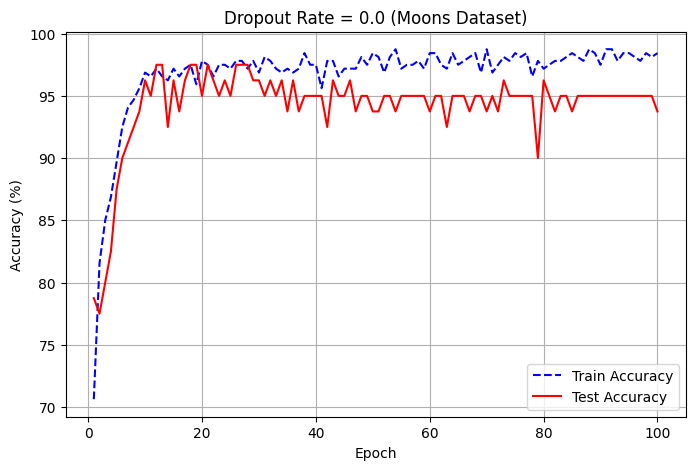

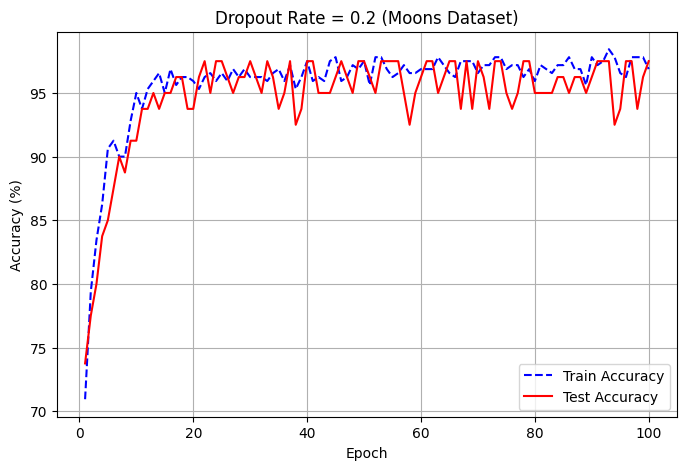

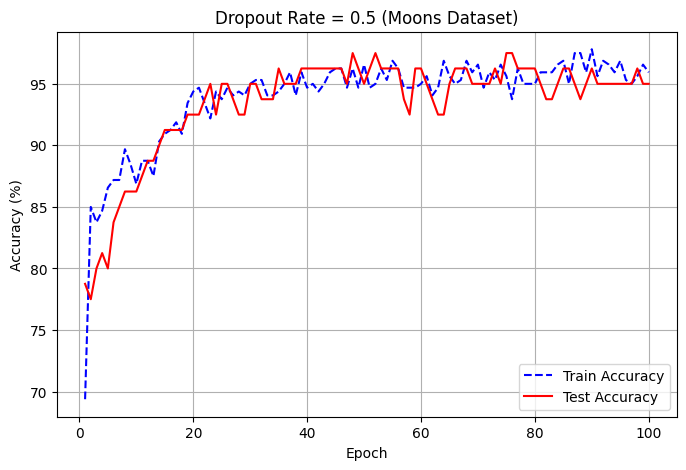

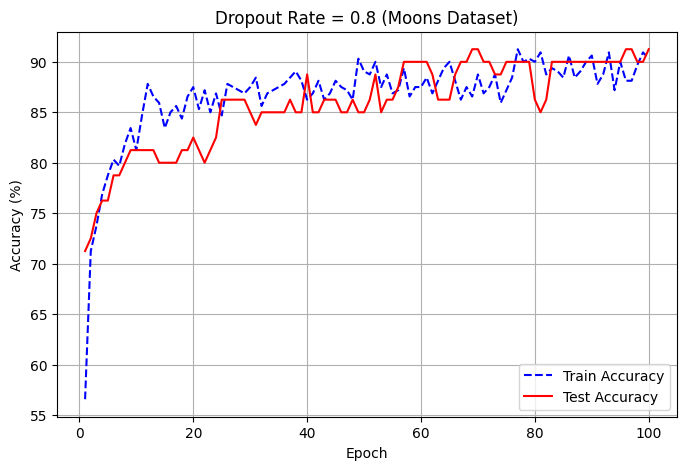

In [49]:
# ------------------------------------------------------------
# 5. رسم چهار نمودار مجزا برای هر نرخ dropout (قسمت الف)
# ------------------------------------------------------------
for dr in dropout_rates:
    train_acc, test_acc = results[dr]
    epochs = range(1, len(train_acc)+1)
    
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_acc, '--', label='Train Accuracy', color='blue')
    plt.plot(epochs, test_acc, '-', label='Test Accuracy', color='red')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.title(f'Dropout Rate = {dr} (Moons Dataset)')
    plt.legend()
    plt.grid(True)
    plt.savefig(f'dropout_accuracy_{dr}.png', dpi=150)
    plt.show()

In [50]:
# ------------------------------------------------------------
# 6. تحلیل نتایج و پاسخ به سوالات (قسمت ب)
# ------------------------------------------------------------
print("\n" + "="*50)
print("Analysis of Results (Part b):")
print("="*50)

best_dr = None
best_test_acc = 0
for dr in dropout_rates:
    final_test_acc = results[dr][1][-1]
    final_train_acc = results[dr][0][-1]
    print(f"Dropout {dr}: Final Train Acc = {final_train_acc:.2f}%, Final Test Acc = {final_test_acc:.2f}%")
    if final_test_acc > best_test_acc:
        best_test_acc = final_test_acc
        best_dr = dr

print(f"\n✅ Best generalization (highest test accuracy) is achieved with dropout_rate = {best_dr}")



Analysis of Results (Part b):
Dropout 0.0: Final Train Acc = 98.44%, Final Test Acc = 93.75%
Dropout 0.2: Final Train Acc = 96.88%, Final Test Acc = 97.50%
Dropout 0.5: Final Train Acc = 95.94%, Final Test Acc = 95.00%
Dropout 0.8: Final Train Acc = 90.31%, Final Test Acc = 91.25%

✅ Best generalization (highest test accuracy) is achieved with dropout_rate = 0.2


پ) ﻣﺮﺯ ﺗﺼﻤﻴﻢ ﺷﺒﻜﻪ ﺭﺍ ﺑﺎ ﻧﺮﺥ dropout ﺻﻔﺮ ﻭ ﻧﺮﺥ ﺑﻬﻴﻨﻪ ﺭﺳﻢ ﻛﺮﺩﻩ ﻭ ﺗﻔﺎﻭﺕ ﺭﺍ ﺗﻮﺿﻴﺢ ﺩﻫﻴﺪ.

In [52]:
def train_model_with_dropout(dropout_rate, train_loader, epochs=100, lr=0.01):
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    model = DropoutMLP(dropout_rate=dropout_rate).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    for epoch in range(epochs):
        model.train()
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(Xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
    return model, device

In [53]:
def plot_decision_boundary(model, X, y, title, filename, device):
    model.eval()
    x_min, x_max = X[:,0].min() - 0.5, X[:,0].max() + 0.5
    y_min, y_max = X[:,1].min() - 0.5, X[:,1].max() + 0.5
    h = 0.01  # گام شبکه
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32).to(device)
    with torch.no_grad():
        preds = torch.sigmoid(model(grid)).cpu().numpy()
    preds = preds.reshape(xx.shape)
    
    plt.figure(figsize=(8,6))
    plt.contourf(xx, yy, preds, levels=np.linspace(0,1,20), alpha=0.6, cmap='RdYlBu')
    plt.scatter(X[:,0], X[:,1], c=y, edgecolors='k', cmap='RdYlBu', alpha=0.8)
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.title(title)
    plt.savefig(filename, dpi=150)
    plt.show()


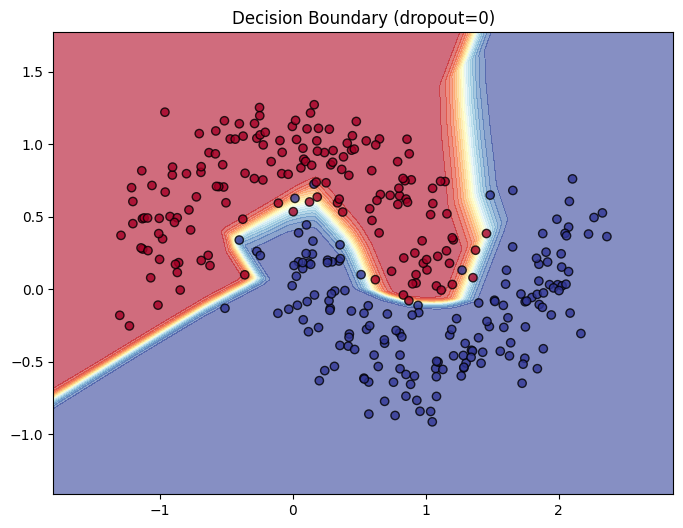

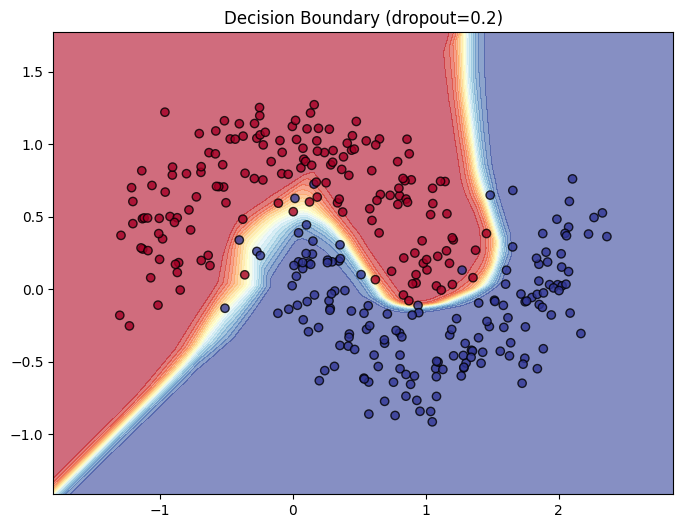

In [54]:
best_dr = 0.2

# آموزش مدل بدون dropout و با best_dr
model0, device0 = train_model_with_dropout(0.0, train_loader, epochs=100)
model_best, device_best = train_model_with_dropout(best_dr, train_loader, epochs=100)

# رسم مرز تصمیم برای dropout=0
plot_decision_boundary(model0, X_train, y_train, 
                       f"Decision Boundary (dropout=0)", 
                       "boundary_dropout0.png", device0)

# رسم مرز تصمیم برای dropout بهینه
plot_decision_boundary(model_best, X_train, y_train, 
                       f"Decision Boundary (dropout={best_dr})", 
                       "boundary_dropout_best.png", device_best)


3-2-3-2 ﺗﺮﻛﻴﺐ dropout ﻭ ﻧﺮﻣﺎﻝ ﺳﺎﺯﻱ ﺩﺳﺘﻪ ﺍﻱ: ﺩﻭ ﻣﺪﻝ ﻣﺸﺎﺑﻪ (ﺑﺎ ﻣﻌﻤﺎﺭﻱ ﺛﺎﺑﺖ) ﺭﻭﻱ moons ﺁﻣﻮﺯﺵ ﺩﻫﻴﺪ: ﻳﻜﻲ ﻓﻘﻂ باdropout  ﺑﻬﻴﻨﻪ، ﻳﻜﻲ ﺑﺎ ﻧﺮﻣﺎﻝ ﺳﺎﺯﻱ ﺩﺳﺘﻪ ﺍﻱ (ﭘﺲ ﺍﺯ ﻫﺮ ﻻﻳﻪ) ﻭ ﻳﻜﻲ ﺑﺎ ﺗﺮﻛﻴﺐ ﻫﺮ ﺩﻭ. ﺩﻗﺖ ﻭ ﺳﺮﻋﺖ ﻫﻤﮕﺮﺍﻳﻲ ﺭﺍ ﻣﻘﺎﻳﺴﻪ ﻛﻨﻴﺪ.


In [55]:
def get_moons_data(n_samples=400, noise=0.1, test_size=0.2, batch_size=64, random_state=42):
    X, y = make_moons(n_samples=n_samples, noise=noise, random_state=random_state)
    y = y.astype(np.float32)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)
    
    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
    X_test_t = torch.tensor(X_test, dtype=torch.float32)
    y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)
    
    train_ds = TensorDataset(X_train_t, y_train_t)
    test_ds = TensorDataset(X_test_t, y_test_t)
    
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)
    return train_loader, test_loader


In [56]:
class DropoutOnly(nn.Module):
    def __init__(self, input_dim=2, hidden1=64, hidden2=64, dropout_rate=0.5):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden1)
        self.bn1 = nn.Identity()   # بدون batch norm
        self.relu1 = nn.ReLU()
        self.drop1 = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.bn2 = nn.Identity()
        self.relu2 = nn.ReLU()
        self.drop2 = nn.Dropout(dropout_rate)
        self.out = nn.Linear(hidden2, 1)
    def forward(self, x):
        x = self.relu1(self.bn1(self.fc1(x)))
        x = self.drop1(x)
        x = self.relu2(self.bn2(self.fc2(x)))
        x = self.drop2(x)
        return self.out(x)

class BatchNormOnly(nn.Module):
    def __init__(self, input_dim=2, hidden1=64, hidden2=64):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden1)
        self.bn1 = nn.BatchNorm1d(hidden1)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.bn2 = nn.BatchNorm1d(hidden2)
        self.relu2 = nn.ReLU()
        self.out = nn.Linear(hidden2, 1)
    def forward(self, x):
        x = self.relu1(self.bn1(self.fc1(x)))
        x = self.relu2(self.bn2(self.fc2(x)))
        return self.out(x)

class DropoutAndBN(nn.Module):
    def __init__(self, input_dim=2, hidden1=64, hidden2=64, dropout_rate=0.5):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden1)
        self.bn1 = nn.BatchNorm1d(hidden1)
        self.relu1 = nn.ReLU()
        self.drop1 = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.bn2 = nn.BatchNorm1d(hidden2)
        self.relu2 = nn.ReLU()
        self.drop2 = nn.Dropout(dropout_rate)
        self.out = nn.Linear(hidden2, 1)
    def forward(self, x):
        x = self.relu1(self.bn1(self.fc1(x)))
        x = self.drop1(x)
        x = self.relu2(self.bn2(self.fc2(x)))
        x = self.drop2(x)
        return self.out(x)


In [57]:
def train_and_evaluate(model, train_loader, test_loader, epochs=100, lr=0.01):
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    train_acc_hist = []
    test_acc_hist = []
    
    for epoch in range(epochs):
        # آموزش
        model.train()
        correct_train = 0
        total_train = 0
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(Xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
            preds = (torch.sigmoid(out) > 0.5).float()
            correct_train += (preds == yb).sum().item()
            total_train += yb.size(0)
        train_acc = correct_train / total_train * 100
        train_acc_hist.append(train_acc)
        
        # ارزیابی
        model.eval()
        correct_test = 0
        total_test = 0
        with torch.no_grad():
            for Xb, yb in test_loader:
                Xb, yb = Xb.to(device), yb.to(device)
                out = model(Xb)
                preds = (torch.sigmoid(out) > 0.5).float()
                correct_test += (preds == yb).sum().item()
                total_test += yb.size(0)
        test_acc = correct_test / total_test * 100
        test_acc_hist.append(test_acc)
        
        if (epoch+1) % 20 == 0:
            print(f"Epoch {epoch+1:3d} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")
    
    return train_acc_hist, test_acc_hist


In [58]:
train_loader, test_loader = get_moons_data(batch_size=64)


In [59]:
best_dropout_rate = 0.2

print("Training Dropout Only...")
model_drop = DropoutOnly(dropout_rate=best_dropout_rate)
train_drop, test_drop = train_and_evaluate(model_drop, train_loader, test_loader, epochs=100)

print("\nTraining BatchNorm Only...")
model_bn = BatchNormOnly()
train_bn, test_bn = train_and_evaluate(model_bn, train_loader, test_loader, epochs=100)

print("\nTraining Dropout + BatchNorm...")
model_both = DropoutAndBN(dropout_rate=best_dropout_rate)
train_both, test_both = train_and_evaluate(model_both, train_loader, test_loader, epochs=100)


Training Dropout Only...
Epoch  20 | Train Acc: 99.06% | Test Acc: 98.75%
Epoch  40 | Train Acc: 100.00% | Test Acc: 100.00%
Epoch  60 | Train Acc: 100.00% | Test Acc: 98.75%
Epoch  80 | Train Acc: 100.00% | Test Acc: 100.00%
Epoch 100 | Train Acc: 100.00% | Test Acc: 98.75%

Training BatchNorm Only...
Epoch  20 | Train Acc: 99.38% | Test Acc: 100.00%
Epoch  40 | Train Acc: 99.69% | Test Acc: 100.00%
Epoch  60 | Train Acc: 100.00% | Test Acc: 100.00%
Epoch  80 | Train Acc: 100.00% | Test Acc: 100.00%
Epoch 100 | Train Acc: 99.69% | Test Acc: 100.00%

Training Dropout + BatchNorm...
Epoch  20 | Train Acc: 99.38% | Test Acc: 100.00%
Epoch  40 | Train Acc: 100.00% | Test Acc: 100.00%
Epoch  60 | Train Acc: 100.00% | Test Acc: 100.00%
Epoch  80 | Train Acc: 100.00% | Test Acc: 100.00%
Epoch 100 | Train Acc: 100.00% | Test Acc: 100.00%


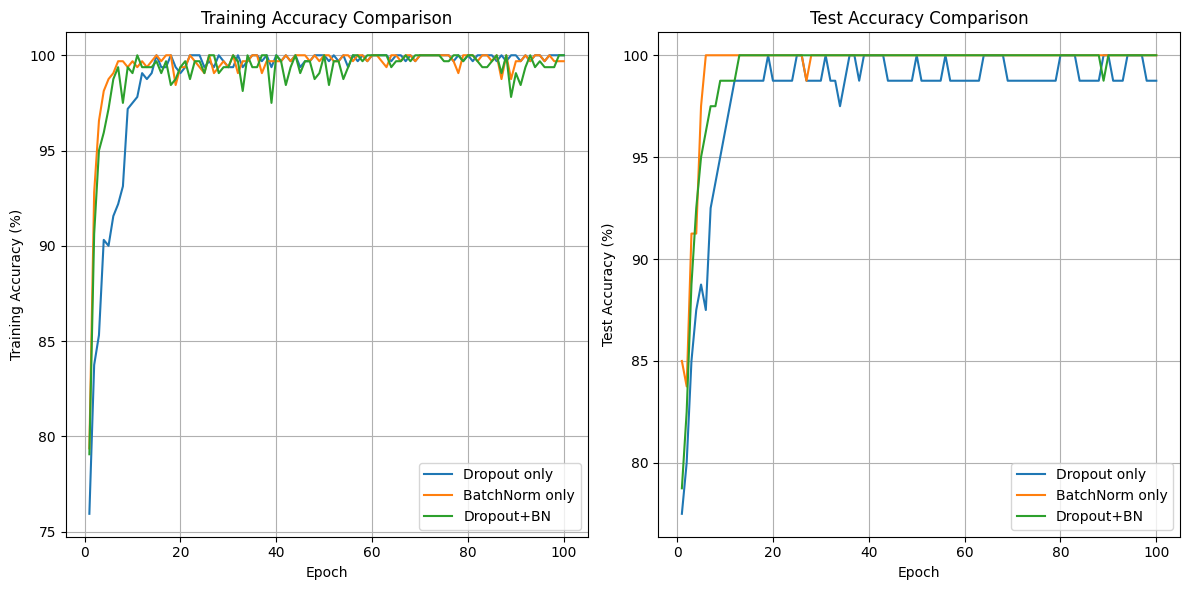

In [60]:
plt.figure(figsize=(12, 6))
epochs = range(1, 101)

plt.subplot(1,2,1)
plt.plot(epochs, train_drop, label='Dropout only')
plt.plot(epochs, train_bn, label='BatchNorm only')
plt.plot(epochs, train_both, label='Dropout+BN')
plt.xlabel('Epoch')
plt.ylabel('Training Accuracy (%)')
plt.title('Training Accuracy Comparison')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(epochs, test_drop, label='Dropout only')
plt.plot(epochs, test_bn, label='BatchNorm only')
plt.plot(epochs, test_both, label='Dropout+BN')
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy (%)')
plt.title('Test Accuracy Comparison')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('dropout_batchnorm_comparison.png', dpi=150)
plt.show()


In [61]:
def epochs_to_reach(acc_hist, target=90):
    for i, acc in enumerate(acc_hist):
        if acc >= target:
            return i+1
    return len(acc_hist)

print("\n=== Convergence Speed (epochs to reach 90% test accuracy) ===")
print(f"Dropout only:      {epochs_to_reach(test_drop, 90)} epochs")
print(f"BatchNorm only:    {epochs_to_reach(test_bn, 90)} epochs")
print(f"Dropout + BN:      {epochs_to_reach(test_both, 90)} epochs")

print("\n=== Final Test Accuracy ===")
print(f"Dropout only:      {test_drop[-1]:.2f}%")
print(f"BatchNorm only:    {test_bn[-1]:.2f}%")
print(f"Dropout + BN:      {test_both[-1]:.2f}%")


=== Convergence Speed (epochs to reach 90% test accuracy) ===
Dropout only:      7 epochs
BatchNorm only:    3 epochs
Dropout + BN:      4 epochs

=== Final Test Accuracy ===
Dropout only:      98.75%
BatchNorm only:    100.00%
Dropout + BN:      100.00%
